In [2]:
import seaborn as sb
import numpy as np
import random
import math
import pandas as pd
import matplotlib.pyplot as plt
import scipy as sc

In [ ]:
1. Начнем с проверки простой гипотезы.
Найдите первые 1000 цифр числа π после запятой. С помощью критерия хи-квадрат проверьте,
можно ли при уровне значимости 0.05 считать эти цифры случайными равномерными?

In [2]:
import mpmath
m = 1000
mpmath.mp.dps = 1001
pi_str = str(mpmath.mp.pi)
digits = pi_str.split('.')[1]
x = [int(a) for a in digits[:1001]]
p_uni = [100]*10
freqs=[0]*10
for a in x:
    for i in range(10):
        if a==i:
            freqs[i]+=1
stat, pval = sc.stats.chisquare(freqs, p_uni)
print(pval)


0.8563586575252496


In [ ]:
2. Проверим однородность и независимость. Использовать данные из файла Priem.csv и встроенный
критерий.
(a) Ответить на вопрос - отличаются ли мальчики и девочки в плане успешности сдачи ЕГЭ?
Для этого попарно проверьте на однородность суммарные баллы, баллы по русскому, баллы
по математике.
(b) Правда ли, что оценки по математике и русскому независимы?

In [3]:
df=pd.read_csv("msudata.csv", sep = ";", encoding="cp1251")

def create_contingency_table(data1, data2, bins):
    freq1 = pd.cut(data1, bins=bins, right=False).value_counts().sort_index()
    freq2 = pd.cut(data2, bins=bins, right=False).value_counts().sort_index()
    contingency_table = pd.DataFrame({'Мужчины': freq1,'Женщины': freq2 }).T
    return contingency_table
men_total = df[df['Пол'] == 'МУЖСКОЙ']['Сумма.баллов']
women_total = df[df['Пол'] == 'ЖЕНСКИЙ']['Сумма.баллов']

men_math = df[df['Пол'] == 'МУЖСКОЙ']["ЕГЭ...матем."]
women_math = df[df['Пол'] == 'ЖЕНСКИЙ']["ЕГЭ...матем."]

men_rus = df[df['Пол'] == 'МУЖСКОЙ']["ЕГЭ...рус.яз."]
women_rus = df[df['Пол'] == 'ЖЕНСКИЙ']["ЕГЭ...рус.яз."]

total = create_contingency_table(men_total, women_total, [0, 300, 320, 340, 360, 380, 400, 410])
chi2_total, p_total, dof_total, expected_total = sc.stats.chi2_contingency(total)
print("total", p_total)

math = create_contingency_table(men_math, women_math, [0, 60, 70, 80, 90, 100])
chi2_total, p_total, dof_total, expected_total = sc.stats.chi2_contingency(math)
print("mat", p_total)

rus = create_contingency_table(men_rus, women_rus, [0, 60, 70, 80, 90, 100])
chi2_total, p_total, dof_total, expected_total = sc.stats.chi2_contingency(rus)
print("rus", p_total)

df_men = df[df['Пол'] == 'МУЖСКОЙ'].dropna(subset=['ЕГЭ...матем.', 'ЕГЭ...рус.яз.'])
math = pd.cut(df_men['ЕГЭ...матем.'], bins=[0, 60, 70, 80, 90, 100])
rus = pd.cut(df_men['ЕГЭ...рус.яз.'], bins= [0, 60, 70, 80, 90, 100])
contingency = pd.crosstab(math, rus)
chi2, pval1, dof, expected = sc.stats.chi2_contingency(contingency)

df_women = df[df['Пол'] == 'ЖЕНСКИЙ'].dropna(subset=['ЕГЭ...матем.', 'ЕГЭ...рус.яз.'])
math = pd.cut(df_women['ЕГЭ...матем.'], bins=[0, 60, 70, 80, 90, 100])
rus = pd.cut(df_women['ЕГЭ...рус.яз.'], bins= [0, 60, 70, 80, 90, 100])
contingency = pd.crosstab(math, rus)
chi2, pval2, dof, expected = sc.stats.chi2_contingency(contingency)

print("\n m")
print(pval1)
print("\n w")
print(pval2)

total 0.22327389396364564
mat 0.5398741280215966
rus 2.4006625517439986e-13

 m
7.06332553528485e-06

 w
0.03163179417786022


In [ ]:
3. Построим критерий Кресси-Рида для проверки простой гипотезы о полиномиальном распреде-
лении. Давайте сравним наши критерии для различных λ. Рассмотрите λ, равные −1, 0, 0.5, 1, 2.
Поcтройте график p-value для каждого из них и выберите наиболее удачный критерий. Исполь-
зуйте исходное равномерное распределение (все pi равны) и неравномерное на свой вкус.

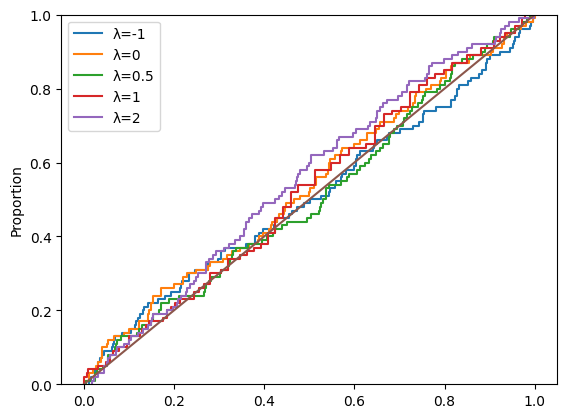

In [13]:
import numpy as np
import scipy as sc
import seaborn as sb
import matplotlib.pyplot as plt

lambd_vals = [-1,0, 0.5, 1, 2]
N = 100  # общее число наблюдений
k = 8   # число исходов
m = 100
probs_exp = [0] * k
probs_exp = np.linspace(3/2, 1/2, k) 
probs_exp /= probs_exp.sum()
probs_exp = [1/k] * k
f_exp = [N/k] * k

for l in lambd_vals:
    pvals = []
    for k in range(m):
        f_obs = np.random.multinomial(n=N, pvals=probs_exp)
        stat, pval = sc.stats.power_divergence(f_obs, f_exp, lambda_=l)
        pvals.append(pval)
    sb.ecdfplot(pvals, label=f'λ={l}')

x = np.linspace(0, 1, 100)
plt.plot(x, x)
plt.legend()
plt.show()

In [ ]:
4. * Переходим к параметрической гипотезе.
Среди 2020 семей, имеющих 2 детей, 527 семей, в которых 2 мальчика, и 476 - две девочки. Можно
ли при уровне значимости 0.05 считать, что количество мальчиков – биномиальная случайная
величина?

В этой задаче нужно сначала найти ОМП для параметрической гипотезы (формулу для нее) на ли-
сточке, затем вычислить ее значение для данных из условия задачи и воспользоваться встроенным

критерием хи-квадрат.
Теперь исследуем работу получившегося критерия на модельных данных (нужно использовать ту
же формулу для ОМП, что и раньше). Рассмотреть следующие распределения:
1) Binom(2, 1/2), Binom(2, 1/8),
2) равномерное распределение R{0, 1, 2},
3) P(X = 0) = P(X = 2) = 3/8, P(X = 1) = 1/4 (X – число мальчиков).

Для каждого распределения сгенерировать по 100 выборок. К каждой выборке применить по-
строенный критерий, получить p-value. Построить графики p-value для каждого распределения,

сравнить их.

0.1084908358500128


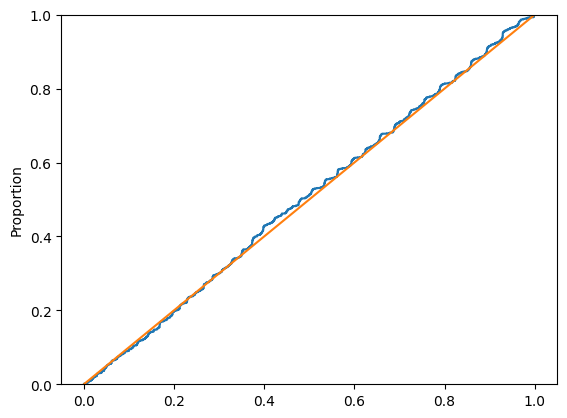

In [9]:
m=1000
p=1/2
bin_size = 2020
mle = 2071/4040
probs = [mle**2, mle*(1-mle) , (1-mle)**2]

f_obs = [2020*mle**2, 2020*2*mle*(1-mle) , 2020*(1-mle)**2]
mle_new = (f_obs[1] + 2*f_obs[2])/(bin_size*2)
f_exp = [2020*1/4,2020*1/2,2020*1/4 ]
stat, pval = sc.stats.chisquare(f_obs, f_exp, ddof=1)
print(pval)
pval = [0]*m
for j in range(m):
    x = np.random.binomial(2,p, size= bin_size)
    f_obs = np.bincount(x, minlength=3)
    mle_new = (f_obs[1] + 2*f_obs[2])/(bin_size*2)
    f_exp = [bin_size* ((1-mle_new)**2),2*bin_size* (mle_new*(1-mle_new)), bin_size* ((mle_new)**2) ]
    stat, pval[j] = sc.stats.chisquare(f_obs, f_exp, ddof=1)
sb.ecdfplot(pval)
x = np.linspace(0, 1, 100)
plt.plot(x, x)

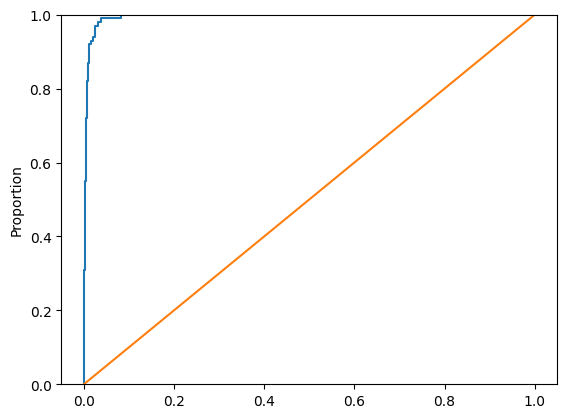

In [52]:
m=100
p=1/8
bin_size = 80
mle = 2071/4040
probs = [mle**2, mle*(1-mle) , (1-mle)**2]
pval = [0]*m
for j in range(m):
    x = np.random.randint(0,2, size= bin_size)
    f_obs = np.bincount(x, minlength=3)
    mle_new = (f_obs[1] + 2*f_obs[2])/(bin_size*2)
    f_exp = [bin_size* ((1-mle_new)**2),2*bin_size* (mle_new*(1-mle_new)), bin_size* ((mle_new)**2) ]
    stat, pval[j] = sc.stats.chisquare(f_obs, f_exp, ddof=1)
sb.ecdfplot(pval)
x = np.linspace(0, 1, 100)
plt.plot(x, x)

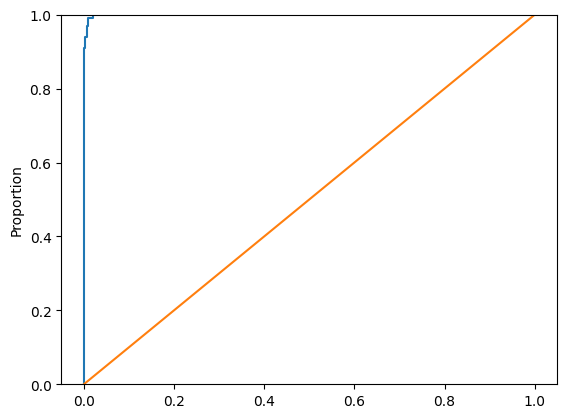

In [57]:
m=100
bin_size = 80
mle = 2071/4040
probs = [mle**2, mle*(1-mle) , (1-mle)**2]
pval = [0]*m
for j in range(m):
    x = np.random.choice([0,1,2], size=bin_size, p=[3/8,1/4,3/8])
    f_obs = np.bincount(x, minlength=3)
    mle_new = (f_obs[1] + 2*f_obs[2])/(bin_size*2)
    f_exp = [bin_size* ((1-mle_new)**2),2*bin_size* (mle_new*(1-mle_new)), bin_size* ((mle_new)**2) ]
    stat, pval[j] = sc.stats.chisquare(f_obs, f_exp, ddof=1)
sb.ecdfplot(pval)
x = np.linspace(0, 1, 100)
plt.plot(x, x)